# code_090 · Modern boosted-tree implementations

**Book:** section 18.4. A self-contained trees-and-ensembles laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_18_GUIDE.md), [run evidence](../CHAPTER_18_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_090).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1890;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1890


<a id="protocol"></a>
## Execute all three libraries on the same evidence boundary

Generate60buildings ×8repeated maintenance records. Features are noisy load, resistance, temperature and material; a building-level random offset induces within-building response dependence. Labels follow an explicitly generated Bernoulli mechanism using clean load before20%load readings are made missing. Ten percent of materials are replaced by a declared missing token. The domain vocabulary steel/concrete/timber plus missing/unknown tokens is declared in advance, not learned from final outcomes. Entire buildings split45development/15final. Within development, the SAME three GroupKFold masks evaluate two depth budgets[3,5] per library. Each candidate has80boosting rounds/learning_rate.1, CPU/thread1; each library receives six fold fits plus one selected full-development fit. Minimum mean fold log loss selects depth. Equal candidate count and rounds do not equalize wall time, number of leaves, parameter semantics or complete tuning quality.

XGBoost3.4.1 uses hist/enable_categorical/depthwise, reg_lambda1; LightGBM4.7.0 uses native categories, leafwise growth with max_depth and num_leaves2**depth, lambda_l2=1,min_child_samples10; CatBoost1.2.10 uses symmetric trees, native string categories, Ordered boosting,l2_leaf_reg1. Other settings remain the explicitly printed defaults/controls. Numeric NaNs are retained. No group identifier is a feature. No early stopping, final-set adaptation or claim of a universal winner occurs. Ordinary execution needs the pinned CPU packages but no network or model download.


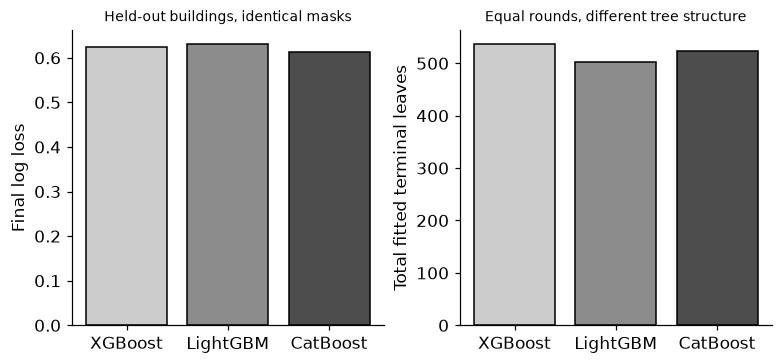

In [2]:
import xgboost as xgb,lightgbm as lgb,catboost as cb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import log_loss,brier_score_loss,accuracy_score
from scipy.special import expit
VERSIONS.update({'xgboost':xgb.__version__,'lightgbm':lgb.__version__,'catboost':cb.__version__})
groups=np.repeat(np.arange(60),8);n=len(groups);load=rng.uniform(0,1,n);resistance=rng.uniform(0,1,n);temperature=rng.normal(0,1,n);material=rng.choice(['steel','concrete','timber'],n).astype(object);offset=rng.normal(0,.7,60);effect=np.array([{'steel':0.,'concrete':-.4,'timber':.6}[v] for v in material]);prob=expit(-1.5+3*load-2*resistance+.3*temperature+effect+offset[groups]);y=rng.binomial(1,prob);observed=load.copy();observed[rng.random(n)<.2]=np.nan;material[rng.random(n)<.1]='__missing__'
levels=['steel','concrete','timber','__missing__','__unknown__'];frame=pd.DataFrame({'load':observed,'resistance':resistance,'temperature':temperature,'material':pd.Categorical(material,categories=levels)});catframe=frame.copy();catframe['material']=catframe['material'].astype(str);order=rng.permutation(60);dev=np.flatnonzero(np.isin(groups,order[:45]));final=np.flatnonzero(np.isin(groups,order[45:]));assert not set(groups[dev])&set(groups[final]);folds=list(GroupKFold(3).split(frame.iloc[dev],y[dev],groups[dev]));ledger=[]
for train,valid in folds:
 assert not set(groups[dev[train]])&set(groups[dev[valid]]);ledger.append({'training_groups':len(np.unique(groups[dev[train]])),'validation_groups':len(np.unique(groups[dev[valid]])),'training_rows':len(train),'validation_rows':len(valid)})
def make(name,depth):
 if name=='XGBoost':return xgb.XGBClassifier(n_estimators=80,max_depth=depth,learning_rate=.1,tree_method='hist',enable_categorical=True,grow_policy='depthwise',reg_lambda=1,n_jobs=1,device='cpu',random_state=SEED,eval_metric='logloss')
 if name=='LightGBM':return lgb.LGBMClassifier(n_estimators=80,max_depth=depth,num_leaves=2**depth,learning_rate=.1,reg_lambda=1,min_child_samples=10,n_jobs=1,random_state=SEED,verbosity=-1)
 return cb.CatBoostClassifier(iterations=80,depth=depth,learning_rate=.1,l2_leaf_reg=1,boosting_type='Ordered',grow_policy='SymmetricTree',loss_function='Logloss',thread_count=1,random_seed=SEED,verbose=False,allow_writing_files=False)
def data(name,ix):return (catframe if name=='CatBoost' else frame).iloc[ix]
def fit_model(name,model,ix):
 if name=='CatBoost':return model.fit(data(name,ix),y[ix],cat_features=['material'])
 return model.fit(data(name,ix),y[ix])
rows=[];fits={};budget=[]
for name in ['XGBoost','LightGBM','CatBoost']:
 options=[]
 for depth in [3,5]:
  scores=[]
  for train,valid in folds:
   model=fit_model(name,make(name,depth),dev[train]);scores.append(float(log_loss(y[dev[valid]],model.predict_proba(data(name,dev[valid]))[:,1])))
  options.append((float(np.mean(scores)),depth,scores))
 score,depth,scores=min(options,key=lambda a:a[0]);model=fit_model(name,make(name,depth),dev);p=model.predict_proba(data(name,final))[:,1];assert np.isfinite(p).all() and np.all((p>=0)&(p<=1));fits[name]=model
 if name=='XGBoost':
  def leaves(node):return 1 if 'leaf' in node else sum(leaves(c) for c in node['children'])
  total_leaves=sum(leaves(json.loads(s)) for s in model.get_booster().get_dump(dump_format='json'));tree_count=len(model.get_booster().get_dump())
 elif name=='LightGBM':
  info=model.booster_.dump_model()['tree_info'];total_leaves=sum(t['num_leaves'] for t in info);tree_count=len(info)
 else:total_leaves=int(model.get_tree_leaf_counts().sum());tree_count=int(model.tree_count_)
 rows.append({'library':name,'selected_depth_budget':depth,'mean_group_fold_log_loss':score,'final_log_loss':float(log_loss(y[final],p)),'final_brier':float(brier_score_loss(y[final],p)),'final_accuracy':float(accuracy_score(y[final],p>=.5)),'fitted_trees':tree_count,'total_terminal_leaves':int(total_leaves)});budget.append({'library':name,'candidate_count':2,'fold_fits_per_candidate':3,'full_development_refits':1,'candidate_scores':[{'depth':d,'mean_log_loss':s,'fold_log_losses':ss} for s,d,ss in options]})
RESULTS['benchmark']=rows;RESULTS['protocol']={'development_buildings':45,'final_buildings':15,'development_rows':len(dev),'final_rows':len(final),'fold_ledger':ledger,'search_budget':budget,'rounds_per_fit':80,'learning_rate':.1,'feature_columns':frame.columns.tolist(),'numeric_missing_training_rows':int(frame.iloc[dev]['load'].isna().sum()),'domain_category_vocabulary':levels,'CPU_threads':1,'equal_wall_time_claimed':False}
fig,axes=plt.subplots(1,2,figsize=(7,3.2));positions=np.arange(3);axes[0].bar(positions,[r['final_log_loss'] for r in rows],color=['.8','.55','.3'],edgecolor='black');axes[0].set(xticks=positions,xticklabels=[r['library'] for r in rows],ylabel='Final log loss',title='Held-out buildings, identical masks');axes[1].bar(positions,[r['total_terminal_leaves'] for r in rows],color=['.8','.55','.3'],edgecolor='black');axes[1].set(xticks=positions,xticklabels=[r['library'] for r in rows],ylabel='Total fitted terminal leaves',title='Equal rounds, different tree structure');plt.show()


<a id="contracts"></a>
## Verify inference representations explicitly

Construct three target-free probes: an ordinary material, a missing-numeric reading, and unseen polymer mapped by the predeclared application policy to __unknown__. All libraries receive the same semantic rows, with their required categorical container. Report probabilities and finiteness rather than claiming identical missing/unseen behavior. Category tokens are not causal material effects. The new category was not learned from training examples. Development folds, final groups and constructor controls are retained above. Primary references: [XGBoost categories](https://xgboost.readthedocs.io/en/stable/tutorials/categorical.html), [LightGBM feature/missing handling](https://lightgbm.readthedocs.io/en/stable/Advanced-Topics.html), [CatBoost categories](https://catboost.ai/docs/en/concepts/algorithm-main-stages_cat-to-numberic), inspected20October2026. Live XGBoost docs3.4.2 versus executed3.4.1; LightGBM4.7.0 and CatBoost1.2.10 execution are recorded. This scoped benchmark is not exhaustive API coverage or a field deployment assessment.


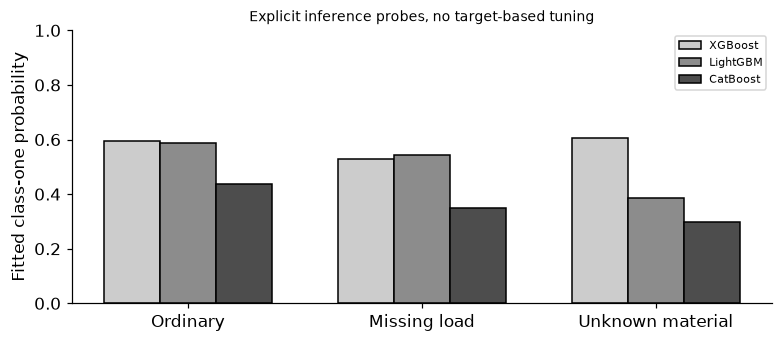

In [3]:
probe=pd.DataFrame({'load':[.6,np.nan,.6],'resistance':[.5,.5,.5],'temperature':[0.,0.,0.],'material':pd.Categorical(['steel','steel','__unknown__'],categories=levels)});probe_cat=probe.copy();probe_cat['material']=probe_cat['material'].astype(str);predictions={}
for name,model in fits.items():
 p=model.predict_proba(probe_cat if name=='CatBoost' else probe)[:,1];assert p.shape==(3,) and np.isfinite(p).all();predictions[name]=p.tolist()
RESULTS['inference_probes']={'rows':['ordinary steel','missing numeric load','unseen material mapped unknown'],'probabilities':predictions,'unseen_material_has_training_examples':False};fig,ax=plt.subplots(figsize=(7,3));pos=np.arange(3)
for j,name in enumerate(fits):ax.bar(pos+(j-1)*.24,predictions[name],width=.24,color=['.8','.55','.3'][j],edgecolor='black',label=name)
ax.set(xticks=pos,xticklabels=['Ordinary','Missing load','Unknown material'],ylabel='Fitted class-one probability',ylim=(0,1),title='Explicit inference probes, no target-based tuning');ax.legend(fontsize=7);plt.show()


In [4]:
summary={'example_id':'code_090','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual XGBoost LightGBM and CatBoost execution', 'common group splits and equal candidate count', 'native categorical and numeric missing contracts', 'growth and leaf-count resource boundaries'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual XGBoost LightGBM and CatBoost execution", "common group splits and equal candidate count", "native categorical and numeric missing contracts", "growth and leaf-count resource boundaries"], "elapsed_seconds": 0.68, "example_id": "code_090", "hardware": "Darwin arm64 CPU", "results": {"benchmark": [{"final_accuracy": 0.65, "final_brier": 0.21698741614818573, "final_log_loss": 0.6240301132202148, "fitted_trees": 80, "library": "XGBoost", "mean_group_fold_log_loss": 0.7037480473518372, "selected_depth_budget": 3, "total_terminal_leaves": 536}, {"final_accuracy": 0.6416666666666667, "final_brier": 0.22030198196364115, "final_log_loss": 0.6300039513851837, "fitted_trees": 80, "library": "LightGBM", "mean_group_fold_log_loss": 0.7039211990528588, "selected_depth_budget": 3, "total_terminal_leaves": 503}, {"final_accuracy": 0.65, "final_brier": 0.21296048585799998, "final_log_loss": 0.6121303036948329, "fitted_trees": 80, "library": "Ca